# Monthly Revenue Forecasting & Budget Variance Analysis
### Real Walmart sales data · Python notebook

**Business question:** Walmart's finance team set a FY2013 revenue budget (Feb 2012 – Jan 2013). Eight months into the year, they need to know:
1. **Are we on budget?** Where are the gaps — which months, store types, stores and departments?
2. **Where will we land?** A forecast for the remaining four months (Oct 2012 – Jan 2013), including the critical holiday season.
3. **How much can we trust the forecast?** Which method would have been most accurate if we had used it at the start of the year?

**Data:** real weekly sales for 45 Walmart stores and 81 departments, Feb 2010 – Oct 2012 (Kaggle *Walmart Recruiting – Store Sales Forecasting*). The **budget is an assumption** (Walmart's internal budget is not public): FY2012 actual × (1 + growth target by store type: A 3.0%, B 2.0%, C 1.5%).

**Workflow:** SQL (database, monthly allocation, budget) → **Python (analysis + forecasting)** → Excel (budget vs actual workbook) → Power BI (dashboard)

## 1. Setup and load from the SQL database

In [1]:
import sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")

BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = BASE / "images"; IMG.mkdir(exist_ok=True)
pd.set_option("display.float_format", "{:,.2f}".format)

BLUE, ORANGE, AQUA, YELLOW, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.edgecolor": "#b5b4ae", "font.size": 10})
money_m = mtick.FuncFormatter(lambda x, _: f"${x/1e6:,.0f}M")
def save(fig, name):
    fig.tight_layout(); fig.savefig(IMG / f"{name}.png", dpi=150, bbox_inches="tight")

con = sqlite3.connect(BASE / "data" / "revenue.db")
total = pd.read_sql("SELECT * FROM vw_monthly_total ORDER BY month_start", con, parse_dates=["month_start"])
store_m = pd.read_sql("SELECT * FROM vw_monthly_store", con, parse_dates=["month_start"])
bva = pd.read_sql("SELECT * FROM vw_bva_store_month", con, parse_dates=["month_start"])
weekly = pd.read_sql("""SELECT week_end_date, SUM(weekly_sales) AS sales, MAX(is_holiday) AS is_holiday
                         FROM weekly_sales GROUP BY week_end_date""", con, parse_dates=["week_end_date"])
stores = pd.read_sql("SELECT * FROM stores", con)
assumptions = pd.read_sql("SELECT * FROM budget_assumptions", con)
total["days"] = total.month_start.dt.days_in_month
total["per_day"] = total.revenue / total.days
print(f"{len(total)} complete months: {total.month_start.min():%b %Y} - {total.month_start.max():%b %Y}")
total.tail(3)

32 complete months: Feb 2010 - Sep 2012


,month_start,fiscal_year,fiscal_month,month_name,revenue,days,per_day
29,2012-07-01,2013,6,Jul,"207,322,391.83",31,"6,687,819.09"
30,2012-08-01,2013,7,Aug,"209,715,966.10",31,"6,765,031.16"
31,2012-09-01,2013,8,Sep,"194,236,013.10",30,"6,474,533.77"


## 2. Data checks
The original files were checked and cleaned by `scripts/01_prepare_data.py`. Weekly sales were spread over the 7 days of each week and summed by month in SQL (`sql/02_transform.sql`).

In [2]:
display(pd.read_csv(BASE / "data" / "clean" / "cleaning_log.csv"))
chk = pd.read_csv(BASE / "sql" / "query_results" / "Q02_check_monthly_allocation_keeps_every_dollar_w.csv")
print("Allocation check (weekly vs monthly, same period):", chk.to_dict("records")[0])

,table,check,rows,action
0,stores,File uses old Mac line endings (\r),1,converted to normal line endings
1,stores,Rows loaded,45,"45 stores, types A/B/C"
2,weekly_sales,Rows loaded,421570,one row per store x department x week
3,weekly_sales,Duplicate store-dept-week rows,0,none found
4,weekly_sales,Negative weekly sales (returns exceed sales),1285,kept - they are real returns/adjustments; flag...
5,weekly_sales,Week-ending day check,421570,all weeks end on Friday (Sat-Fri weeks)
6,weekly_sales,Store-dept-weeks with no row,99665,not every store has every department every wee...
7,store_week_features,Weeks after last sales week (competition test ...,1755,removed - no sales to compare against
8,store_week_features,Markdown data missing before Nov 2011,4140,left blank (NULL) - Walmart only provided mark...
9,store_week_features,Negative markdown values,23,kept as provided (small adjustments)


Allocation check (weekly vs monthly, same period): {'weekly_sales_in_period': 6552233278.0, 'monthly_sales_total': 6552233278.0}


## 3. Revenue trend and growth

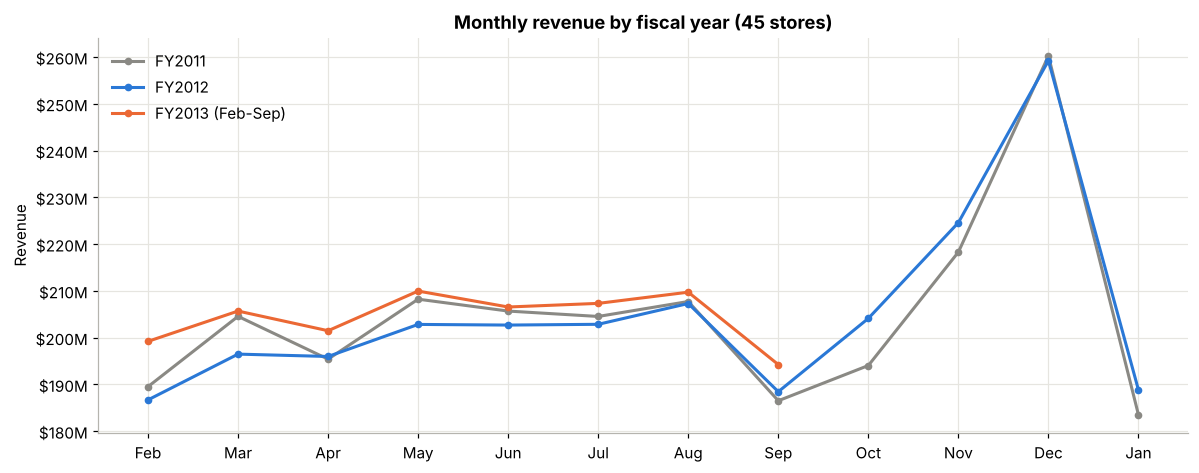

FY2011 $2.458B  ->  FY2012 $2.460B  (+0.07%)
Feb-Sep: FY2012 $1.583B -> FY2013 $1.634B (+3.22%)


In [3]:
fy_colors = {2011: GRAY, 2012: BLUE, 2013: ORANGE}
months = ["Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec","Jan"]
fig, ax = plt.subplots(figsize=(11, 4.4))
for fy, g in total.groupby("fiscal_year"):
    ax.plot(g.fiscal_month, g.revenue, marker="o", ms=4, lw=2, color=fy_colors[fy],
            label=f"FY{fy}" + (" (Feb-Sep)" if fy == 2013 else ""))
ax.set_xticks(range(1, 13), months); ax.yaxis.set_major_formatter(money_m)
ax.set(title="Monthly revenue by fiscal year (45 stores)", ylabel="Revenue"); ax.legend(frameon=False)
save(fig, "01_monthly_revenue_by_fy"); plt.show()

fy = total.groupby("fiscal_year").revenue.agg(["count", "sum"])
same = total[total.fiscal_month <= 8].groupby("fiscal_year").revenue.sum()
print(f"FY2011 ${fy.loc[2011,'sum']/1e9:.3f}B  ->  FY2012 ${fy.loc[2012,'sum']/1e9:.3f}B  "
      f"({fy.loc[2012,'sum']/fy.loc[2011,'sum']-1:+.2%})")
print(f"Feb-Sep: FY2012 ${same[2012]/1e9:.3f}B -> FY2013 ${same[2013]/1e9:.3f}B ({same[2013]/same[2012]-1:+.2%})")

**Insight — trend:** FY2012 revenue was flat versus FY2011 (+0.07%), but growth came back in 2012: **Feb–Sep of FY2013 is running +3.2% ahead** of the same months a year earlier. The three years follow almost exactly the same seasonal shape.

## 4. Seasonality and holidays

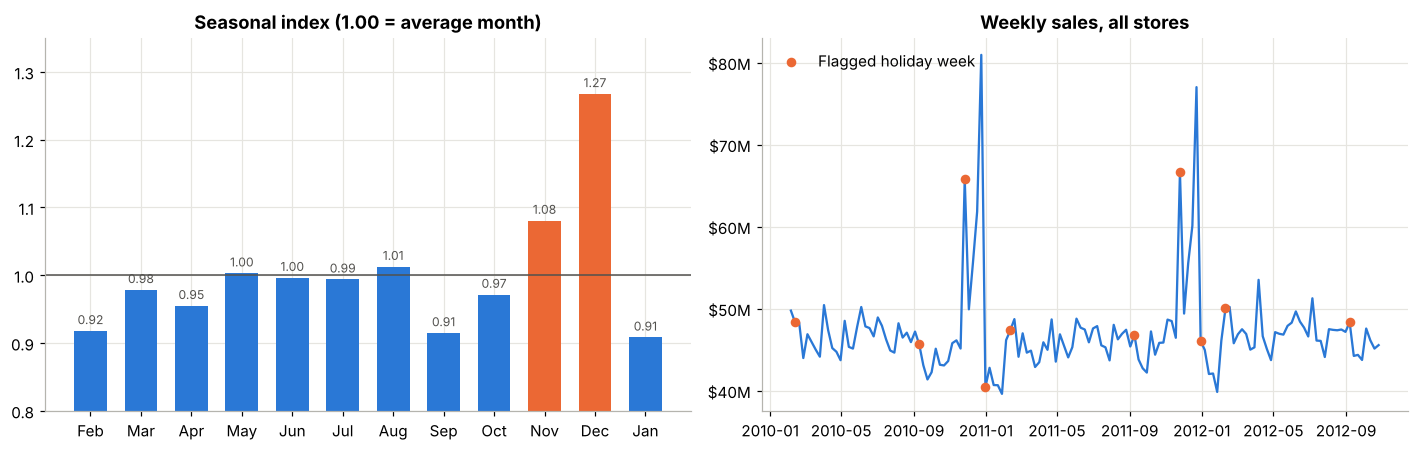

   week_end_date  sales_$M  is_holiday
46    2010-12-24     80.90           0
98    2011-12-23     77.00           0
94    2011-11-25     66.60           1
42    2010-11-26     65.80           1


In [4]:
idx = (total[total.fiscal_year.isin([2011, 2012])]
       .assign(ix=lambda d: d.revenue / d.groupby("fiscal_year").revenue.transform("mean"))
       .groupby("fiscal_month").ix.mean())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].bar(months, idx.values, color=[ORANGE if v > 1.05 else BLUE for v in idx.values], width=0.65)
ax[0].axhline(1, color=INK, lw=1)
for i, v in enumerate(idx.values): ax[0].text(i, v + 0.01, f"{v:.2f}", ha="center", fontsize=8, color=INK)
ax[0].set(title="Seasonal index (1.00 = average month)", ylim=(0.8, 1.35))

ax[1].plot(weekly.week_end_date, weekly.sales, color=BLUE, lw=1.5)
h = weekly[weekly.is_holiday == 1]
ax[1].scatter(h.week_end_date, h.sales, color=ORANGE, s=28, zorder=3, label="Flagged holiday week")
ax[1].yaxis.set_major_formatter(money_m); ax[1].legend(frameon=False, loc="upper left")
ax[1].set(title="Weekly sales, all stores")
save(fig, "02_seasonality"); plt.show()
print(weekly.nlargest(4, "sales").assign(sales=lambda d: (d.sales/1e6).round(1)).rename(columns={"sales": "sales_$M"}))

**Insight — seasonality:** December is **27% above an average month** and November 8% above; January, February and September are the weakest months (about 9% below average).

The biggest weeks of all are the **weeks just before Christmas** (week ending 24 Dec 2010: $80.9M; 23 Dec 2011: $77.0M). Walmart's holiday flag marks the Christmas week itself, which is actually slow. Only the Thanksgiving week shows a real spike among flagged weeks. For monthly forecasting, the **monthly seasonal pattern matters far more than the holiday flag**.

## 5. Where does revenue come from?

,revenue,stores,share,sqft,revenue_per_sqft
store_type,,,,,
A,"$1,585,604,756",22,64.5%,"3,899,450",$407
B,"$727,260,275",17,29.6%,"1,720,242",$423
C,"$147,080,209",6,6.0%,"243,250",$605


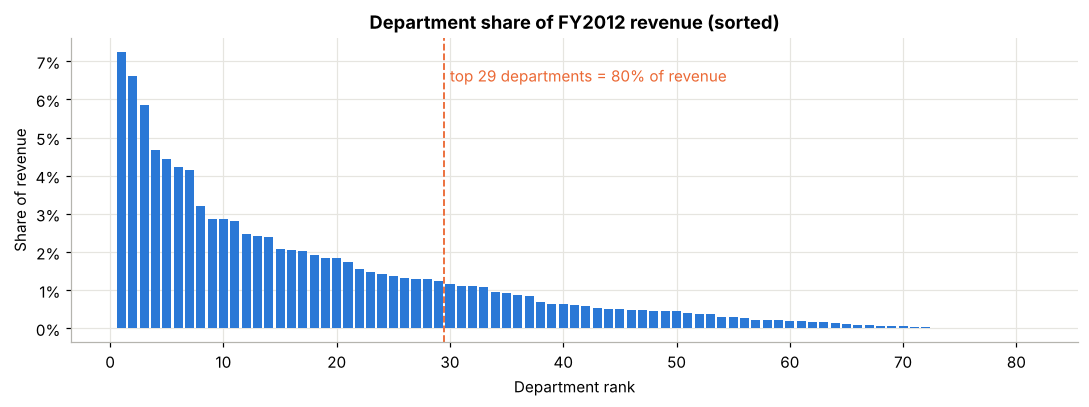

In [5]:
fy12 = store_m[store_m.fiscal_year == 2012]
by_type = fy12.groupby("store_type").agg(revenue=("revenue", "sum"), stores=("store_id", "nunique"))
by_type["share"] = by_type.revenue / by_type.revenue.sum()
by_type["sqft"] = stores.groupby("store_type").size_sqft.sum()
by_type["revenue_per_sqft"] = by_type.revenue / by_type.sqft
display(by_type.style.format({"revenue": "${:,.0f}", "share": "{:.1%}", "sqft": "{:,.0f}", "revenue_per_sqft": "${:,.0f}"}))

dept = pd.read_sql("SELECT dept_id, SUM(revenue) AS revenue FROM monthly_sales WHERE fiscal_year = 2012 GROUP BY dept_id",
                   con).sort_values("revenue", ascending=False).reset_index(drop=True)
dept["cum_share"] = dept.revenue.cumsum() / dept.revenue.sum()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(1, len(dept) + 1), dept.revenue / dept.revenue.sum(), color=BLUE, width=0.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set(title="Department share of FY2012 revenue (sorted)", xlabel="Department rank", ylabel="Share of revenue")
n80 = (dept.cum_share < 0.8).sum() + 1
ax.axvline(n80 + 0.5, color=ORANGE, ls="--", lw=1.2)
ax.text(n80 + 1, ax.get_ylim()[1] * 0.85, f"top {n80} departments = 80% of revenue", color=ORANGE)
save(fig, "03_department_pareto"); plt.show()

**Insight — mix:** the 22 large Type A stores produce **64.5% of revenue**, but the small Type C stores sell the most per square foot ($605 vs $407 for Type A). Revenue is spread widely: it takes **29 of 81 departments** to reach 80% of sales, so no single department drives the total.

## 6. Budget vs actual — FY2013 year to date (Feb – Sep 2012)
Budget = FY2012 actual for the same store, department and month × (1 + growth target). Variance = actual − budget (positive = favourable).

,budget,actual,variance,variance_pct
month,,,,
Feb 2012,"$191,568,815","$199,201,114","$7,632,299",+3.98%
Mar 2012,"$201,609,624","$205,680,671","$4,071,047",+2.02%
Apr 2012,"$201,097,376","$201,473,803","$376,426",+0.19%
May 2012,"$208,126,691","$209,954,666","$1,827,975",+0.88%
Jun 2012,"$207,982,155","$206,547,918","$-1,434,237",-0.69%
Jul 2012,"$208,154,840","$207,322,392","$-832,448",-0.40%
Aug 2012,"$212,719,373","$209,715,966","$-3,003,407",-1.41%
Sep 2012,"$193,364,986","$194,236,013","$871,027",+0.45%


YTD budget $1,624.6M | actual $1,634.1M | variance $+9.5M (+0.59%)
Leap day effect: Feb 2012 had one extra day worth about $6.9M = 90% of February's $7.6M favourable variance


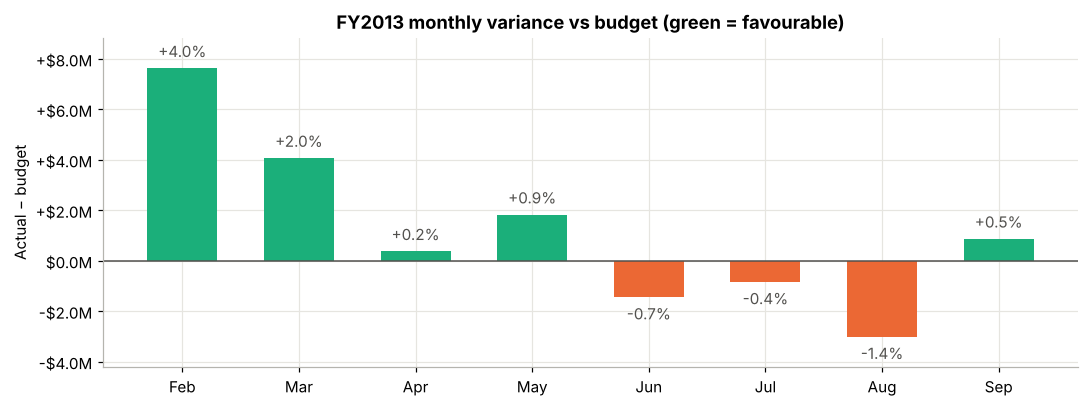

In [6]:
mb = bva.groupby("month_start").agg(budget=("budget", "sum"), actual=("actual", "sum")).reset_index()
ytd = mb[mb.actual > 0].copy()
ytd["variance"] = ytd.actual - ytd.budget
ytd["variance_pct"] = ytd.variance / ytd.budget
ytd["days"] = ytd.month_start.dt.days_in_month
display(ytd.assign(month=ytd.month_start.dt.strftime("%b %Y")).set_index("month")
        [["budget", "actual", "variance", "variance_pct"]]
        .style.format({"budget": "${:,.0f}", "actual": "${:,.0f}", "variance": "${:,.0f}", "variance_pct": "{:+.2%}"}))
tot_b, tot_a = ytd.budget.sum(), ytd.actual.sum()
print(f"YTD budget ${tot_b/1e6:,.1f}M | actual ${tot_a/1e6:,.1f}M | variance ${(tot_a-tot_b)/1e6:+,.1f}M ({tot_a/tot_b-1:+.2%})")

# February 2012 had 29 days (leap year) vs 28 in the budget's base year
feb = ytd.iloc[0]
leap_effect = feb.actual / 29
print(f"Leap day effect: Feb 2012 had one extra day worth about ${leap_effect/1e6:.1f}M "
      f"= {leap_effect/feb.variance:.0%} of February's ${feb.variance/1e6:.1f}M favourable variance")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(ytd.month_start.dt.strftime("%b"), ytd.variance, width=0.6,
       color=[AQUA if v >= 0 else ORANGE for v in ytd.variance])
ax.axhline(0, color=INK, lw=1)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{'+' if x > 0 else '-' if x < 0 else ''}${abs(x)/1e6:,.1f}M"))
lo, hi = ytd.variance.min(), ytd.variance.max(); ax.set_ylim(lo - 1.2e6, hi + 1.2e6)
for i, (v, p) in enumerate(zip(ytd.variance, ytd.variance_pct)):
    ax.text(i, v + (3e5 if v >= 0 else -3e5), f"{p:+.1%}", ha="center", va="bottom" if v >= 0 else "top", color=INK)
ax.set(title="FY2013 monthly variance vs budget (green = favourable)", ylabel="Actual − budget")
save(fig, "04_monthly_variance"); plt.show()

,budget,actual,variance,variance_pct,growth_target,actual_growth_vs_LY
store_type,,,,,,
A,"$1,053,365,246","$1,051,820,256","$-1,544,990",-0.15%,3.0%,+2.85%
B,"$473,479,633","$480,636,630","$7,156,997",+1.51%,2.0%,+3.54%
C,"$97,778,981","$101,675,656","$3,896,675",+3.99%,1.5%,+5.54%


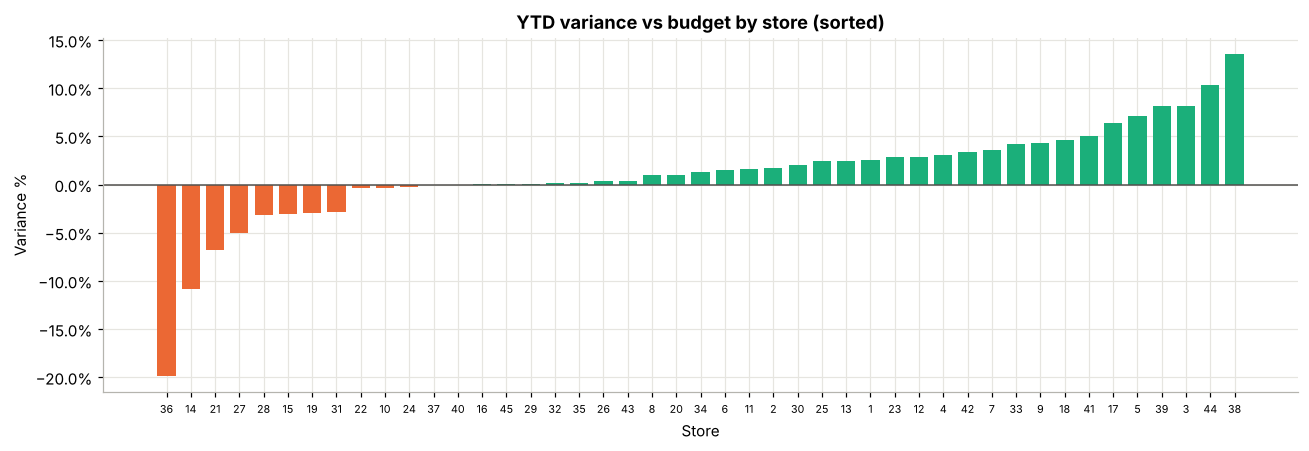

32 of 45 stores are at or above budget
Biggest $ shortfalls:
 store_id store_type      variance  variance_pct
       14          A -7,660,483.92         -0.11
       27          A -3,102,843.00         -0.05
       36          A -2,664,868.50         -0.20


In [7]:
st = bva[bva.actual.notna()].groupby(["store_id", "store_type"]).agg(budget=("budget", "sum"), actual=("actual", "sum")).reset_index()
st["variance"] = st.actual - st.budget; st["variance_pct"] = st.variance / st.budget
tp = st.groupby("store_type")[["budget", "actual", "variance"]].sum()
tp["variance_pct"] = tp.variance / tp.budget
tp["growth_target"] = assumptions.set_index("store_type").growth_target
tp["actual_growth_vs_LY"] = tp.actual / (tp.budget / (1 + tp.growth_target)) - 1
display(tp.style.format({"budget": "${:,.0f}", "actual": "${:,.0f}", "variance": "${:,.0f}", "variance_pct": "{:+.2%}",
                         "growth_target": "{:.1%}", "actual_growth_vs_LY": "{:+.2%}"}))

s = st.sort_values("variance_pct")
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(s.store_id.astype(str), s.variance_pct, color=[AQUA if v >= 0 else ORANGE for v in s.variance_pct], width=0.75)
ax.axhline(0, color=INK, lw=1); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title="YTD variance vs budget by store (sorted)", xlabel="Store", ylabel="Variance %")
ax.tick_params(axis="x", labelsize=7)
save(fig, "05_store_variance"); plt.show()
print(f"{(st.variance >= 0).sum()} of {len(st)} stores are at or above budget")
print("Biggest $ shortfalls:"); print(st.nsmallest(3, "variance")[["store_id", "store_type", "variance", "variance_pct"]].to_string(index=False))

**Insight — budget vs actual (YTD):**
- The company is **$9.5M (+0.59%) ahead of budget** after eight months, and 32 of 45 stores are at or above budget.
- But **$6.9M of February's $7.6M beat is the leap day**: Feb 2012 had 29 days and the budget was built from a 28-day February. Without that extra day the YTD lead is only about **+$2.6M (+0.16%)**. The budget method should have adjusted for trading days.
- Momentum has slowed: Feb–May were favourable, **Jun–Aug were all behind budget**.
- **Type A stores are slightly behind (-0.15%)**: they grew 2.85% against a 3.0% target. Types B and C beat their lower targets comfortably.
- **Store 14 alone is $7.7M short (-10.8%)**, almost as much as the entire company's YTD lead.

## 7. Forecasting
**Set-up.** The series is monthly company revenue, Feb 2010 – Sep 2012 (32 months). Models forecast **revenue per day** and multiply by the days in the month, so the leap day and 30- vs 31-day months are handled correctly.

**Backtest.** Each model is trained only on Feb 2010 – Jan 2012 (what finance would have known when setting the budget) and asked to predict Feb – Sep 2012. Those predictions are compared with what really happened. The budget itself is scored the same way.

| Model | Idea |
|---|---|
| Seasonal naïve | Same month last year |
| Seasonal naïve + trend | Same month last year × recent 12-month growth |
| Holt-Winters | Exponential smoothing with damped trend and multiplicative seasonality |
| SARIMA (1,0,0)(0,1,0)12 | Last year's month plus a short-memory correction for recent momentum |
| Regression | log(revenue/day) = trend + month effects (least squares) |

In [8]:
y = total.set_index("month_start").per_day.asfreq("MS")
days = total.set_index("month_start").days.asfreq("MS")
train_end, test_start = "2012-01-01", "2012-02-01"

def fit_forecast(series, h, model):
    """Return a forecast of revenue PER DAY for the next h months."""
    idx = pd.date_range(series.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    if model == "Seasonal naive":
        return pd.Series([series[d - pd.DateOffset(years=1)] for d in idx], idx)
    if model == "Seasonal naive + trend":
        g = series[-12:].sum() / series[-24:-12].sum() if len(series) >= 24 else 1.0
        return pd.Series([series[d - pd.DateOffset(years=1)] * g for d in idx], idx)
    if model == "Holt-Winters":
        m = ExponentialSmoothing(series, trend="add", damped_trend=True, seasonal="mul",
                                 seasonal_periods=12, initialization_method="estimated").fit(optimized=True)
        return pd.Series(m.forecast(h).values, idx)
    if model == "SARIMA":
        m = SARIMAX(np.log(series), order=(1, 0, 0), seasonal_order=(0, 1, 0, 12), trend="c").fit(disp=False)
        return pd.Series(np.exp(m.get_forecast(h).predicted_mean.values), idx)
    if model == "Regression":
        d = pd.DataFrame({"y": np.log(series.values), "t": range(len(series)),
                          "m": series.index.month.astype(str)})
        fit = smf.ols("y ~ t + C(m)", d).fit()
        nd = pd.DataFrame({"t": range(len(series), len(series) + h), "m": idx.month.astype(str)})
        return pd.Series(np.exp(fit.predict(nd).values), idx)

MODELS = ["Seasonal naive", "Seasonal naive + trend", "Holt-Winters", "SARIMA", "Regression"]
actual_test = total.set_index("month_start").revenue[test_start:]
bt = {}
for m in MODELS:
    bt[m] = fit_forecast(y[:train_end], len(actual_test), m) * days[actual_test.index]
budget_m = mb.set_index("month_start").budget[actual_test.index]

def score(pred):
    e = pred - actual_test
    return pd.Series({"MAPE": (e.abs() / actual_test).mean(), "MAE": e.abs().mean(), "Bias": e.sum() / actual_test.sum()})
scores = pd.DataFrame({m: score(p) for m, p in bt.items()}).T
scores.loc["Budget (LY x growth target)"] = score(budget_m)
scores = scores.sort_values("MAPE")
display(scores.style.format({"MAPE": "{:.2%}", "MAE": "${:,.0f}", "Bias": "{:+.2%}"}))

,MAPE,MAE,Bias
Budget (LY x growth target),1.23%,"$2,506,108",-0.58%
Holt-Winters,1.27%,"$2,564,457",-1.26%
Regression,2.02%,"$4,091,937",-2.00%
SARIMA,2.36%,"$4,807,761",-2.35%
Seasonal naive + trend,2.65%,"$5,398,020",-2.64%
Seasonal naive,2.71%,"$5,531,349",-2.71%


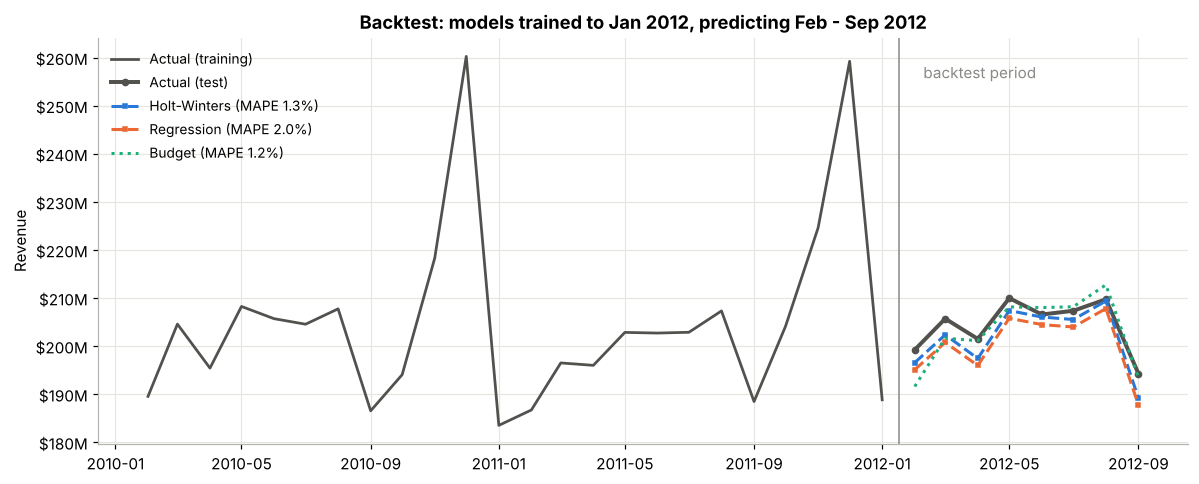

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
hist = total.set_index("month_start").revenue
ax.plot(hist[:"2012-01-01"].index, hist[:"2012-01-01"], color=INK, lw=1.8, label="Actual (training)")
ax.plot(actual_test.index, actual_test, color=INK, lw=2.6, marker="o", ms=4, label="Actual (test)")
best_two = [m for m in scores.index if m in bt][:2]
for m, col in zip(best_two, [BLUE, ORANGE]):
    ax.plot(bt[m].index, bt[m], color=col, lw=2, ls="--", marker="s", ms=3, label=f"{m} (MAPE {scores.loc[m,'MAPE']:.1%})")
ax.plot(budget_m.index, budget_m, color=AQUA, lw=2, ls=":", label=f"Budget (MAPE {scores.loc['Budget (LY x growth target)','MAPE']:.1%})")
ax.axvline(pd.Timestamp(test_start) - pd.Timedelta(days=15), color=GRAY, lw=1)
ax.text(pd.Timestamp(test_start), ax.get_ylim()[1] * 0.98, "  backtest period", color=GRAY, va="top")
ax.yaxis.set_major_formatter(money_m); ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.set(title="Backtest: models trained to Jan 2012, predicting Feb - Sep 2012", ylabel="Revenue")
save(fig, "06_backtest"); plt.show()

**Insight — which method works?** Surprisingly, the **budget method itself (last year × growth target) was the most accurate** for Feb–Sep 2012 (MAPE 1.23%), just ahead of **Holt-Winters (1.27%)**, the best statistical model. Every statistical model **under-predicted** (negative bias): they were trained on a flat 2011 and could not know growth would return in 2012. Two lessons: a simple last-year baseline is hard to beat for a stable retailer, and statistical forecasts should be combined with business judgment about growth.

### Forecast for the rest of FY2013 (Oct 2012 – Jan 2013)
The best backtest model is refitted on all 32 months. The forecast range (80%) comes from that model's own backtest errors: ±1.28 × the standard deviation of its monthly % error, a simple, honest way to show uncertainty.

In [10]:
best = scores.index[0] if scores.index[0] in MODELS else scores.index[1]
print("Model used:", best)
future_idx = pd.date_range("2012-10-01", "2013-01-01", freq="MS")
fdays = pd.Series(future_idx.days_in_month, future_idx)
fc = fit_forecast(y, 4, best) * fdays
pct_err = (bt[best] - actual_test) / actual_test
band = 1.28 * pct_err.std(ddof=1)
fc_tbl = pd.DataFrame({"forecast": fc, "lower_80": fc * (1 - band), "upper_80": fc * (1 + band),
                       "budget": mb.set_index("month_start").budget[future_idx]})
fc_tbl["forecast_vs_budget"] = fc_tbl.forecast - fc_tbl.budget
fc_tbl["last_year"] = hist[future_idx - pd.DateOffset(years=1)].values
display(fc_tbl.assign(month=fc_tbl.index.strftime("%b %Y")).set_index("month")
        .style.format("${:,.0f}"))
print(f"Forecast range: +/-{band:.2%} per month")

Model used: Holt-Winters


,forecast,lower_80,upper_80,budget,forecast_vs_budget,last_year
month,,,,,,
Oct 2012,"$203,386,860","$201,197,375","$205,576,345","$209,453,811","$-6,066,951","$204,113,660"
Nov 2012,"$226,185,388","$223,750,474","$228,620,302","$230,454,493","$-4,269,105","$224,588,948"
Dec 2012,"$265,190,328","$262,335,521","$268,045,135","$265,999,128","$-808,801","$259,221,337"
Jan 2013,"$189,780,875","$187,737,860","$191,823,890","$193,733,500","$-3,952,625","$188,806,902"


Forecast range: +/-1.08% per month


FY2013 budget          $2.524B
FY2013 latest estimate $2.519B  (range $2.509B - $2.528B)
Expected variance      $-5.6M (-0.22%)
FY2013 vs FY2012       +2.39%


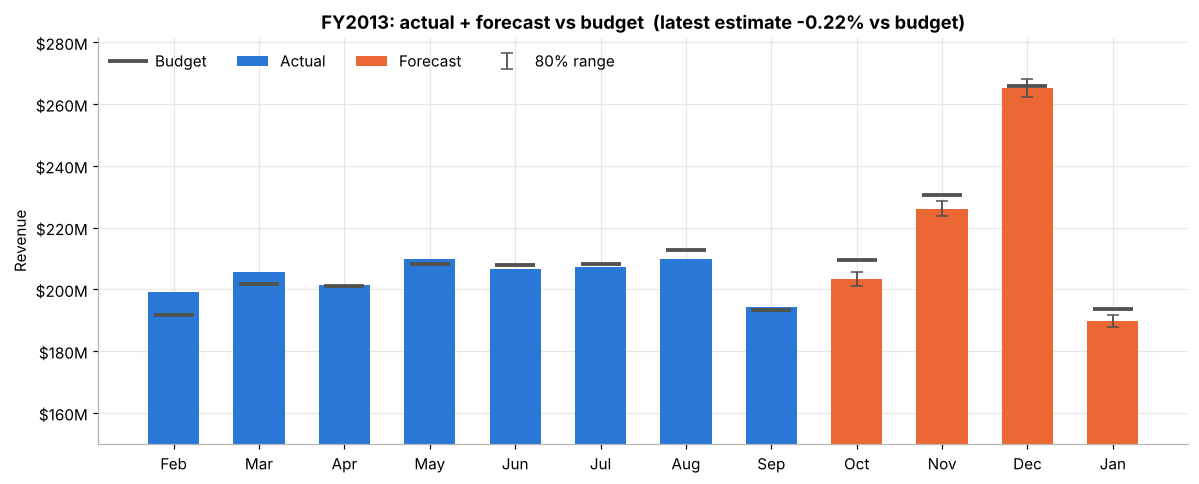

In [11]:
le = pd.concat([ytd.set_index("month_start").actual, fc])
budget_all = mb.set_index("month_start").budget
full = pd.DataFrame({"budget": budget_all, "latest_estimate": le})
full["basis"] = np.where(full.index <= "2012-09-01", "Actual", "Forecast")
fy_budget, fy_le = full.budget.sum(), full.latest_estimate.sum()
fy_low = ytd.actual.sum() + fc_tbl.lower_80.sum(); fy_high = ytd.actual.sum() + fc_tbl.upper_80.sum()
print(f"FY2013 budget          ${fy_budget/1e9:,.3f}B")
print(f"FY2013 latest estimate ${fy_le/1e9:,.3f}B  (range ${fy_low/1e9:,.3f}B - ${fy_high/1e9:,.3f}B)")
print(f"Expected variance      ${(fy_le-fy_budget)/1e6:+,.1f}M ({fy_le/fy_budget-1:+.2%})")
print(f"FY2013 vs FY2012       {fy_le/fy.loc[2012,'sum']-1:+.2%}")

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(12); lab = full.index.strftime("%b")
ax.bar(x[:8], full.latest_estimate[:8], color=BLUE, width=0.6, label="Actual")
ax.bar(x[8:], full.latest_estimate[8:], color=ORANGE, width=0.6, label="Forecast")
ax.errorbar(x[8:], fc_tbl.forecast, yerr=[fc_tbl.forecast - fc_tbl.lower_80, fc_tbl.upper_80 - fc_tbl.forecast],
            fmt="none", ecolor=INK, capsize=4, lw=1.2, label="80% range")
ax.plot(x, full.budget, color=INK, lw=0, marker="_", ms=26, mew=2.5, label="Budget")
ax.set_xticks(x, lab); ax.yaxis.set_major_formatter(money_m); ax.set_ylim(150e6, None)
ax.legend(frameon=False, ncol=4, loc="upper left")
ax.set(title=f"FY2013: actual + forecast vs budget  (latest estimate {fy_le/fy_budget-1:+.2%} vs budget)", ylabel="Revenue")
save(fig, "07_latest_estimate"); plt.show()

**Insight — where will FY2013 land?** Holt-Winters projects **$2.519B, about $5.6M (-0.22%) below budget**. The YTD lead is used up because each of the remaining months forecasts below budget, especially **October (-$6.1M) and November (-$4.3M)**. December, the biggest month, is expected to be close to budget. The 80% range for the full year is roughly $2.509B – $2.528B, i.e. between about 0.6% below and 0.2% above budget.

### Forecast by store type and by store
Store types use the same best model. For individual stores (too short and noisy for heavy models) the forecast is a simple, explainable **run-rate**: the store's own month last year × the store's year-to-date growth versus last year.

In [12]:
type_rows, type_fc = [], {}
for t in ["A", "B", "C"]:
    s = store_m[store_m.store_type == t].groupby("month_start").revenue.sum().asfreq("MS")
    f = fit_forecast(s / s.index.days_in_month, 4, best) * fdays
    type_fc[t] = f
    b = bva[bva.store_type == t].groupby("month_start").budget.sum()
    ytd_a = bva[(bva.store_type == t) & bva.actual.notna()].actual.sum()
    type_rows.append({"store_type": t, "fy_budget": b.sum(), "ytd_actual": ytd_a, "forecast_oct_jan": f.sum(),
                      "latest_estimate": ytd_a + f.sum()})
tt = pd.DataFrame(type_rows).set_index("store_type")
tt["variance"] = tt.latest_estimate - tt.fy_budget; tt["variance_pct"] = tt.variance / tt.fy_budget
display(tt.style.format({c: "${:,.0f}" for c in tt.columns if c != "variance_pct"} | {"variance_pct": "{:+.2%}"}))

# store-level run-rate forecast
sm_ = store_m.set_index(["store_id", "month_start"]).revenue
store_rows, store_fc_rows = [], []
for sid in sorted(store_m.store_id.unique()):
    s = sm_.loc[sid]
    g = s["2012-02-01":"2012-09-01"].sum() / s["2011-02-01":"2011-09-01"].sum()
    for d in future_idx:
        store_fc_rows.append({"store_id": sid, "month_start": d, "forecast": s[d - pd.DateOffset(years=1)] * g})
    b = bva[bva.store_id == sid]
    f_sum = sum(r["forecast"] for r in store_fc_rows[-4:])
    store_rows.append({"store_id": sid, "store_type": b.store_type.iloc[0], "fy_budget": b.budget.sum(),
                       "latest_estimate": b.actual.sum() + f_sum, "ytd_growth": g - 1})
stf = pd.DataFrame(store_rows)
stf["variance"] = stf.latest_estimate - stf.fy_budget; stf["variance_pct"] = stf.variance / stf.fy_budget
print("Stores expected to miss full-year budget by the most:")
display(stf.nsmallest(5, "variance").style.format({"fy_budget": "${:,.0f}", "latest_estimate": "${:,.0f}",
        "variance": "${:,.0f}", "variance_pct": "{:+.2%}", "ytd_growth": "{:+.2%}"}))
print(f"Sum of store run-rate forecasts (Oct-Jan): ${sum(r['forecast'] for r in store_fc_rows)/1e6:,.1f}M "
      f"vs company model ${fc.sum()/1e6:,.1f}M")

,fy_budget,ytd_actual,forecast_oct_jan,latest_estimate,variance,variance_pct
store_type,,,,,,
A,"$1,633,172,899","$1,051,820,256","$566,793,904","$1,618,614,160","$-14,558,739",-0.89%
B,"$741,805,481","$480,636,630","$266,408,822","$747,045,452","$5,239,972",+0.71%
C,"$149,286,412","$101,675,656","$51,955,373","$153,631,029","$4,344,617",+2.91%


Stores expected to miss full-year budget by the most:


,store_id,store_type,fy_budget,latest_estimate,ytd_growth,variance,variance_pct
13,14,A,"$109,522,798","$97,697,530",-8.12%,"$-11,825,268",-10.80%
26,27,A,"$94,670,930","$89,946,391",-2.14%,"$-4,724,539",-4.99%
35,36,A,"$19,253,459","$15,432,429",-17.44%,"$-3,821,030",-19.85%
20,21,B,"$41,114,554","$38,307,089",-4.96%,"$-2,807,466",-6.83%
18,19,A,"$77,338,816","$75,057,404",-0.04%,"$-2,281,412",-2.95%


Sum of store run-rate forecasts (Oct-Jan): $905.8M vs company model $884.5M


In [13]:
# Two scenarios for the rest of the year
rr = sum(r["forecast"] for r in store_fc_rows)
ytd_actual = ytd.actual.sum()
scen = pd.DataFrame({
    "Oct-Jan forecast": [fc.sum(), rr],
    "FY2013 latest estimate": [ytd_actual + fc.sum(), ytd_actual + rr],
}, index=[f"Cautious: {best} (statistical)", "Momentum: store run-rate (YTD growth continues)"])
scen["vs budget $"] = scen["FY2013 latest estimate"] - fy_budget
scen["vs budget %"] = scen["vs budget $"] / fy_budget
scen["Oct-Jan growth vs LY"] = scen["Oct-Jan forecast"] / fc_tbl.last_year.sum() - 1
display(scen.style.format({"Oct-Jan forecast": "${:,.0f}", "FY2013 latest estimate": "${:,.0f}",
                           "vs budget $": "${:+,.0f}", "vs budget %": "{:+.2%}", "Oct-Jan growth vs LY": "{:+.2%}"}))
print(f"Budget needs Oct-Jan growth vs LY of {fc_tbl.budget.sum()/fc_tbl.last_year.sum()-1:+.2%}")

,Oct-Jan forecast,FY2013 latest estimate,vs budget $,vs budget %,Oct-Jan growth vs LY
Cautious: Holt-Winters (statistical),"$884,543,451","$2,518,675,993","$-5,588,799",-0.22%,+0.89%
Momentum: store run-rate (YTD growth continues),"$905,767,803","$2,539,900,345","$+15,635,553",+0.62%,+3.31%


Budget needs Oct-Jan growth vs LY of +2.61%


**Insight — scenarios and risk:**
- **Cautious case (Holt-Winters): -0.22% vs budget.** It assumes Oct–Jan grows only +0.9% on last year, and in the backtest this model leaned low by about 1.3%.
- **Momentum case (store run-rate): +0.62% vs budget.** It assumes each store keeps its YTD growth (+3.3% on last year overall).
- The budget needs **+2.6% growth on last year for Oct–Jan**. YTD growth has been +3.2%, so budget is achievable, but only if the holiday season keeps the same pace.
- **Risk is concentrated in Type A stores** (about -0.9% vs budget in the cautious case) and in a handful of stores. **Store 14 is heading for about -$11.8M**, Store 27 -$4.7M and Store 36 -$3.8M.

## 8. What else moves sales? (temperature, fuel, CPI, unemployment)

In [14]:
feat = pd.read_sql("""SELECT f.store_id, f.week_end_date, f.temperature_f, f.fuel_price, f.cpi, f.unemployment_rate,
                             f.is_holiday, SUM(w.weekly_sales) AS sales
                      FROM store_week_features f JOIN weekly_sales w USING (store_id, week_end_date)
                      GROUP BY f.store_id, f.week_end_date""", con)
feat = feat[feat.is_holiday == 0]
# compare each store with itself: sales and drivers as deviations from the store's own average
cols = ["temperature_f", "fuel_price", "cpi", "unemployment_rate"]
dev = feat.groupby("store_id")[cols + ["sales"]].transform(lambda s: (s - s.mean()) / s.std())
corr = dev[cols].corrwith(dev.sales).rename("correlation with store's weekly sales")
display(corr.to_frame().style.format("{:+.3f}"))

,correlation with store's weekly sales
temperature_f,-0.107
fuel_price,-0.001
cpi,+0.066
unemployment_rate,-0.060


**Insight — external drivers:** comparing each store with itself, weekly sales have **almost no relationship** with fuel price, CPI or unemployment (correlations within ±0.07) and only a weak negative link with temperature (-0.11). Over this horizon, **calendar and seasonality drive sales; macro data adds little** to a monthly forecast. (The SQL markdown query reaches a similar conclusion for promotions: weeks with the biggest markdowns did not sell more than a store's normal weeks.)

## 9. Save forecasts to the database and run the forecast SQL queries

In [15]:
rows = []
for m, p in bt.items():
    rows += [{"level": "Total", "level_value": "All", "model": m, "purpose": "Backtest", "month_start": d,
              "forecast": v, "lower_80": None, "upper_80": None} for d, v in p.items()]
rows += [{"level": "Total", "level_value": "All", "model": best, "purpose": "Forecast", "month_start": d,
          "forecast": r.forecast, "lower_80": r.lower_80, "upper_80": r.upper_80} for d, r in fc_tbl.iterrows()]
for t, f in type_fc.items():
    rows += [{"level": "Store type", "level_value": t, "model": best, "purpose": "Forecast", "month_start": d,
              "forecast": v, "lower_80": v * (1 - band), "upper_80": v * (1 + band)} for d, v in f.items()]
rows += [{"level": "Store", "level_value": str(r["store_id"]), "model": "Store run-rate", "purpose": "Forecast",
          "month_start": r["month_start"], "forecast": r["forecast"], "lower_80": None, "upper_80": None}
         for r in store_fc_rows]
fdf = pd.DataFrame(rows)
fdf["month_start"] = pd.to_datetime(fdf.month_start).dt.strftime("%Y-%m-%d")
fdf[["forecast", "lower_80", "upper_80"]] = fdf[["forecast", "lower_80", "upper_80"]].astype(float).round(2)
con.execute("DELETE FROM forecast"); fdf.to_sql("forecast", con, if_exists="append", index=False); con.commit()
print(f"wrote {len(fdf)} forecast rows")

import re
text = (BASE / "sql" / "05_forecast_queries.sql").read_text()
for block in re.split(r"\n(?=-- Q\d\d:)", text)[1:]:
    title = block.splitlines()[0].replace("-- ", "")
    q = pd.read_sql(block, con)
    slug = re.sub(r"[^a-z0-9]+", "_", title.split(":", 1)[1].lower()).strip("_")[:45]
    q.to_csv(BASE / "sql" / "query_results" / f"{title.split(':')[0]}_{slug}.csv", index=False)
    print("\n" + title); display(q)

wrote 236 forecast rows

Q20: Backtest — how close was each model (and the budget) to actual Feb - Sep 2012?


,model,months,mape_pct,mae,bias_pct
0,Budget (LY x growth target),8,1.23,"2,506,108.00",-0.58
1,Holt-Winters,8,1.27,"2,564,457.00",-1.26
2,Regression,8,2.02,"4,091,937.00",-2.00
3,SARIMA,8,2.36,"4,807,761.00",-2.35
4,Seasonal naive + trend,8,2.65,"5,398,020.00",-2.64
5,Seasonal naive,8,2.71,"5,531,349.00",-2.71



Q21: Full-year FY2013 latest estimate = actual (Feb-Sep) + forecast (Oct-Jan) vs budget


,month_start,fiscal_month,budget,actual,forecast,latest_estimate,variance_vs_budget,basis,cumulative_variance
0,2012-02-01,1,"191,568,815.00","199,201,114.00",NaN,"199,201,114.00","7,632,299.00",Actual,"7,632,299.00"
1,2012-03-01,2,"201,609,624.00","205,680,671.00",NaN,"205,680,671.00","4,071,047.00",Actual,"11,703,346.00"
2,2012-04-01,3,"201,097,376.00","201,473,803.00",NaN,"201,473,803.00","376,426.00",Actual,"12,079,772.00"
3,2012-05-01,4,"208,126,691.00","209,954,666.00",NaN,"209,954,666.00","1,827,975.00",Actual,"13,907,747.00"
4,2012-06-01,5,"207,982,155.00","206,547,918.00",NaN,"206,547,918.00","-1,434,237.00",Actual,"12,473,510.00"
5,2012-07-01,6,"208,154,840.00","207,322,392.00",NaN,"207,322,392.00","-832,448.00",Actual,"11,641,062.00"
6,2012-08-01,7,"212,719,373.00","209,715,966.00",NaN,"209,715,966.00","-3,003,407.00",Actual,"8,637,655.00"
7,2012-09-01,8,"193,364,986.00","194,236,013.00",NaN,"194,236,013.00","871,027.00",Actual,"9,508,682.00"
8,2012-10-01,9,"209,453,811.00",NaN,"203,386,860.00","203,386,860.00","-6,066,951.00",Forecast,"3,441,732.00"
9,2012-11-01,10,"230,454,493.00",NaN,"226,185,388.00","226,185,388.00","-4,269,105.00",Forecast,"-827,373.00"



Q22: Latest estimate vs budget by store type (full FY2013)


,store_type,fy2013_budget,ytd_actual,forecast_oct_jan,latest_estimate,variance,variance_pct
0,A,"1,633,172,899.00","1,051,820,256.00","566,793,904.00","1,618,614,160.00","-14,558,739.00",-0.89
1,B,"741,805,481.00","480,636,630.00","266,408,822.00","747,045,452.00","5,239,972.00",0.71
2,C,"149,286,412.00","101,675,656.00","51,955,373.00","153,631,029.00","4,344,617.00",2.91


## 10. Export for Power BI and Excel

In [16]:
out = BASE / "data" / "powerbi"; out.mkdir(exist_ok=True)
q = lambda s: pd.read_sql(s, con)
q("""SELECT m.store_id, m.dept_id, m.month_start, m.fiscal_year, m.fiscal_month, ROUND(m.revenue, 2) AS revenue
     FROM monthly_sales m""").to_csv(out / "fact_monthly_sales.csv", index=False)
q("SELECT * FROM budget").to_csv(out / "fact_budget.csv", index=False)
fdf.to_csv(out / "fact_forecast.csv", index=False)
q("SELECT * FROM store_week_features").to_csv(out / "fact_store_week_features.csv", index=False)
q("""SELECT store_id, week_end_date, SUM(weekly_sales) AS weekly_sales, MAX(is_holiday) AS is_holiday
     FROM weekly_sales GROUP BY store_id, week_end_date""").to_csv(out / "fact_weekly_store_sales.csv", index=False)
q("SELECT * FROM stores").to_csv(out / "dim_store.csv", index=False)
q("SELECT * FROM departments").to_csv(out / "dim_department.csv", index=False)
q("SELECT * FROM budget_assumptions").to_csv(out / "dim_budget_assumptions.csv", index=False)
q("""SELECT DISTINCT month_start, fiscal_year, fiscal_month, fiscal_quarter, month_name, calendar_year, calendar_month
     FROM calendar WHERE month_start BETWEEN '2010-02-01' AND '2013-01-01'""").to_csv(out / "dim_month.csv", index=False)
scores.rename_axis("model").reset_index().to_csv(out / "model_backtest_scores.csv", index=False)
stf.to_csv(out / "store_latest_estimate.csv", index=False)
print(sorted(p.name for p in out.iterdir()))

['dim_budget_assumptions.csv', 'dim_department.csv', 'dim_month.csv', 'dim_store.csv', 'fact_budget.csv', 'fact_forecast.csv', 'fact_monthly_sales.csv', 'fact_store_week_features.csv', 'fact_weekly_store_sales.csv', 'model_backtest_scores.csv', 'store_latest_estimate.csv']


## Summary

| Question | Answer |
|---|---|
| **Are we on budget?** | Yes, slightly: **+$9.5M (+0.59%) YTD**, but most of that is February's leap day. Underlying performance is about on budget, and Jun–Aug fell behind. |
| **Where are the gaps?** | Type A stores (-0.15%) vs B (+1.5%) and C (+4.0%). Store 14 (-$7.7M) is the biggest single gap. |
| **Where will we land?** | Between **-0.22% (cautious, Holt-Winters)** and **+0.62% (momentum, run-rate)** vs the $2.524B budget, effectively on budget, with risk in Oct–Nov. |
| **Best forecasting method?** | Holt-Winters was the best statistical model (MAPE 1.27%); the simple last-year × growth method was just as good (1.23%). All models under-predicted the 2012 rebound. |

### Recommendations
1. **Build budgets on trading days** (revenue per day × days in month) so leap years and calendar shifts don't create false variances.
2. **Act on the Oct–Nov gap now**: the cautious forecast is $10.3M behind budget across those two months. Focus pre-holiday promotions and staffing on Type A stores.
3. **Run a store review for Store 14** (and 27, 36): together they explain more than the company's entire YTD lead.
4. **Set growth targets by recent store performance**, not only by store type: Type C stores beat a 1.5% target by growing 5.5%.
5. **Use a forecast range, not a single number**, and update it monthly (rolling forecast) as actuals arrive.